# Классификатор: будет ли продажа на неделе

Первая ступень модели. CatBoost по признакам пары на неделю отсчёта T даёт вероятность, что на неделе T + h (h = 1...9) будет хотя бы одна продажа. Количество тут не прогнозируется - это `04_regressor.ipynb`; вместе их собирает `01_start.ipynb`.

Зачем отдельно: по SMAPE (половина скора) решение "0 или не 0" важнее количества - на неделях без продаж любой ненулевой прогноз даёт 200 %, а пропущенная продажа - тоже 200 %.

Код - `src/classifier.py` (модель, метрики, отбор признаков, анализ ошибок), признаки - `src/features.py`. Все метрики сравниваются с простым правилом: "доля недель с продажами за последние 8 недель".

In [1]:
import sys; sys.path.insert(0, "../src")   # код проекта - в src/

import numpy as np
import pandas as pd
from core import *

# правки в src/ подхватываются без перезапуска ядра (методы, объявленные в ноутбуке, после этого перезапусти);
# на Kaggle не включаем: там старый IPython, и это расширение на новом Python не грузится
if not ON_KAGGLE:
    %load_ext autoreload
    %autoreload 2

import classifier, regressor
from features import GROUPS, overview, select

## Признаки

Общий запас признаков считается в `src/features.py` - одним кодом для обучения и прогноза, всё только по данным до недели отсчёта, окна не длиннее 24 недель. У каждой модели свой набор - список `FEATURES` в `src/classifier.py`; стартовые наборы выбраны на глаз, проверять их - разделом "Какие группы признаков помогают" ниже.

Поменять набор: насовсем - `classifier.FEATURES = select("лаги", "частота", ..., extra=["mean4"])` или правка списка в `src/classifier.py`; на один эксперимент - `features=[...]` в вызове (пример в конце).

In [2]:
overview(("классификатор", classifier.FEATURES), ("регрессор", regressor.FEATURES))

,признаки,что значат,классификатор,регрессор
лаги,"lag1, lag2, lag3, lag4",продажи пары за 1-4 последние недели,все,все
уровень,"mean4, mean8, mean13, mean24, med8, max8","средние за 4/8/13/24 недели, медиана и максиму...",2 из 6,все
частота,"nz4, nz8, nz13, nz24, ewm_nz, days4, days8",доля недель с продажами (4-24 недели; сглаженн...,все,1 из 7
обычное количество,"typ8, typ24, qty_per_day8, max_day8","сколько продают, когда продают: за неделю (8/2...",нет,все
давность,"since_last, since_first, days_since_sale, hist...","недель с последней и первой продажи, дней с по...",все,нет
тренды,"trend, art_trend, wh_trend","4 недели к 24: у пары, у товара на всех склада...",все,все
товар на всех складах,"art_mean4, art_nz4",продажи того же товара по всем складам и доля ...,все,все
остатки,"stock, stock_min7, stock_mean28, stock_le0_28,...","остаток на начало дня T, минимум за 7 дней, ср...",все,2 из 6
цена и скидка,"price8, price_trend, discount8","средняя цена за штуку за 8 недель, она же к 24...",1 из 3,все
география,"cities8, divisions8",в скольких городах и департаментах покупают за...,нет,все


## Настройки

Локально (WSL, ~8 ГБ памяти): каждая 4-я неделя отсчёта и 500 деревьев, обучение на фолде ~2 минуты. На Kaggle (`make run NB=03` из папки проекта) настройки полные: все недели отсчёта, 400 деревьев, GPU. В обоих случаях глубина 6, lr 0.1 и без комбинаций категорий. Выводы ниже сохранены с более раннего прогона на Kaggle, ещё с 1500 деревьями глубины 8 и lr 0.05 (видно в следующей ячейке). По кривой из раздела "Сколько нужно деревьев" больше 400 деревьев не нужно, а глубина 8 на сезонных фолдах хуже. Поменять можно прямо тут, например `classifier.PARAMS["iterations"] = 300`.

In [3]:
classifier.PARAMS, classifier.ORIGIN_STEP, classifier.ABLATION

({'iterations': 1500,
  'learning_rate': 0.05,
  'depth': 8,
  'loss_function': 'Logloss',
  'random_seed': 42,
  'verbose': 0,
  'allow_writing_files': False,
  'thread_count': -1,
  'task_type': 'GPU'},
 1,
 {'origin_step': 2, 'iterations': 500})

## Обучение и метрики на главном фолде

Модель учится на истории до отсечки фолда `season2025` и прогнозирует его 9 недель; метрики - по факту этих недель.

| Метрика | Что значит | Хорошо |
|---|---|---|
| ROC AUC | как часто у недели с продажей вероятность выше, чем у недели без | 1; 0.5 - монетка |
| PR AUC | точность "будет продажа" по всем порогам | 1; "наугад" = доля недель с продажами |
| logloss, Brier | насколько честны сами вероятности | меньше |
| precision | из недель с ответом "будет продажа" - доля, где она была | больше |
| recall | из недель с продажей - доля пойманных | больше |
| specificity | из недель без продаж - доля правильно обнулённых | больше |
| balanced accuracy, F1, MCC | общий итог решений при пороге | больше |

ROC AUC, PR AUC, logloss и Brier от порога не зависят - это и есть "насколько модель отличает" неделю с продажей от недели без. Остальное - про решения при конкретном пороге.

In [4]:
THRESHOLD = 0.55   # вероятность выше порога - "будет продажа"

m = classifier.evaluate("season2025", threshold=THRESHOLD)
display(m["summary"])
m["confusion"]

,ROC AUC,PR AUC,logloss,Brier,accuracy,balanced accuracy,precision,recall,specificity,F1,MCC,"доля ""будет продажа""",доля недель с продажами
"CatBoost, порог 0.55",0.8381,0.8362,0.4896,0.1577,0.7710,0.7504,0.8532,0.5791,0.9217,0.6899,0.5432,0.2986,0.4399
"простое правило, >= 0.5",0.8059,0.7784,0.9171,0.1765,0.7548,0.7441,0.7554,0.6547,0.8335,0.7014,0.4989,0.3813,0.4399


,прогноз: 0,прогноз: будет продажа
факт: продаж не было,40837,3467
факт: продажа была,14647,20150


Как порог меняет решения: чем он выше, тем больше недель обнуляем - растёт specificity, падает recall.

In [5]:
m["thresholds"]

,precision,recall,specificity,balanced accuracy,"доля ""будет продажа"""
порог,,,,,
0.30,0.6933,0.7744,0.7310,0.7527,0.4913
0.40,0.7727,0.6821,0.8424,0.7623,0.3883
0.50,0.8312,0.6116,0.9024,0.7570,0.3237
0.55,0.8532,0.5791,0.9217,0.7504,0.2986
0.60,0.8720,0.5464,0.9370,0.7417,0.2756
0.65,0.8905,0.5125,0.9505,0.7315,0.2532
0.70,0.9076,0.4768,0.9619,0.7193,0.2311
0.80,0.9402,0.4041,0.9798,0.6920,0.1891


## Где различает хуже

По горизонту (неделя через 1 и через 9 недель) и по типу пары - где модель добавляет то, чего не видит простое правило.

In [6]:
display(m["by_horizon"])
m["by_segment"]

,ROC AUC,ROC AUC (простое правило),PR AUC,balanced accuracy,доля недель с продажами
"горизонт, недель",,,,,
1,0.8490,0.8196,0.8277,0.7554,0.4037
2,0.8495,0.8183,0.8425,0.7608,0.4278
3,0.8424,0.8143,0.8476,0.7521,0.4540
4,0.8423,0.8135,0.8464,0.7614,0.4461
5,0.8389,0.8061,0.8396,0.7557,0.4410
6,0.8317,0.7980,0.8325,0.7450,0.4476
7,0.8296,0.7952,0.8209,0.7429,0.4281
8,0.8352,0.7980,0.8341,0.7460,0.4394
9,0.8294,0.7941,0.8398,0.7366,0.4714


,пар,доля недель с продажами,ROC AUC,ROC AUC (простое правило),precision,recall,specificity
не продавалась 8 недель,1677.0,0.1630,0.6697,0.5000,0.9452,0.0280,0.9997
продажи < 50 % недель,3761.0,0.2823,0.6723,0.5830,0.6606,0.0762,0.9846
продажи >= 50 % недель,3351.0,0.7554,0.8282,0.7712,0.8624,0.8495,0.5813


## Калибровка и кривые

Если модель говорит 0.7, продажа должна быть примерно в 70 % таких недель - от этого зависит выбор порога.

,недель,средняя вероятность,доля с продажей
вероятность,,,
0.0-0.1,9534.0,0.0549,0.1004
0.1-0.2,17529.0,0.1493,0.1840
0.2-0.3,13173.0,0.2459,0.2785
0.3-0.4,8148.0,0.3462,0.3941
0.4-0.5,5112.0,0.4461,0.4797
0.5-0.6,3801.0,0.5488,0.5969
0.6-0.7,3522.0,0.6495,0.6877
0.7-0.8,3324.0,0.7492,0.7608
0.8-0.9,4506.0,0.8544,0.8711


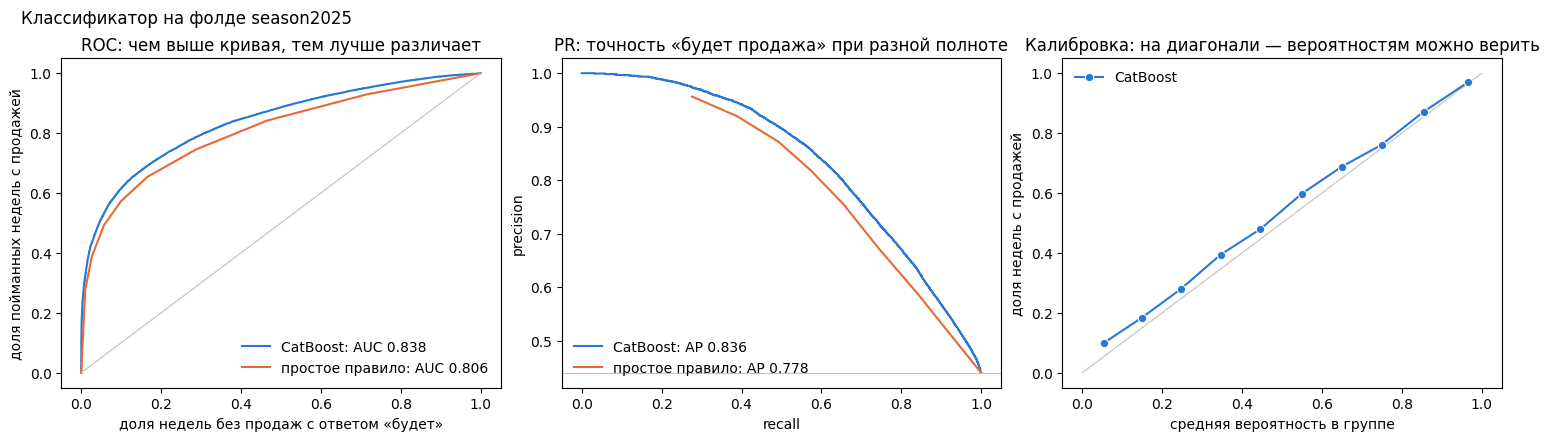

In [7]:
display(m["calibration"])
classifier.plot_curves("season2025")

## Все фолды

Здесь видно, держится ли улучшение метрик классификатора на всех фолдах. В модель изменение берём по итоговому score: не хуже на обоих сезонных фолдах, а на `recent` хуже не больше чем на 0.005. Модели для остальных фолдов обучатся при первом вызове.

In [8]:
classifier.summary(threshold=THRESHOLD)

ROC AUC  PR AUC  logloss   Brier  \
season2025 CatBoost          0.8381  0.8362   0.4896  0.1577   
           простое правило   0.8059  0.7784   0.9171  0.1765   
season2024 CatBoost          0.8675  0.7777   0.4292  0.1287   
           простое правило   0.8241  0.6981   0.9151  0.1462   
recent     CatBoost          0.8660  0.8777   0.4503  0.1476   
           простое правило   0.8403  0.8286   0.7388  0.1625   

                            balanced accuracy  precision  recall  specificity  \
season2025 CatBoost                    0.7504     0.8532  0.5791       0.9217   
           простое правило             0.7441     0.7554  0.6547       0.8335   
season2024 CatBoost                    0.7503     0.7786  0.5704       0.9302   
           простое правило             0.7321     0.7313  0.5515       0.9128   
recent     CatBoost                    0.7844     0.8163  0.7244       0.8444   
           простое правило             0.7624     0.7483  0.7730       0.7518   

                               MCC  
season2025 CatBoost         0.5432  
           простое правило  0.4989  
season2024 CatBoost         0.5539  
           простое правило  0.5084  
recent     CatBoost         0.5737  
           простое правило  0.5246

## CatBoost против простых правил: сколько ещё можно выжать

Для каждого варианта - ROC AUC и итог (SMAPE, score) при лучшем пороге, если там, где "будет продажа", ставить "сколько пара обычно продаёт за неделю".

**Потолок** - "оракул": знает, как часто пара будет продаваться в неделях теста, но не в какие именно. Лучше него модель, которая оценивает вероятность продажи для пары, не сделает: в какую именно неделю случится продажа - во многом случайность. "Закрыто разрыва до потолка" - какую часть пути от простого правила (0) до потолка (1) прошёл вариант по score.

In [9]:
rules = classifier.rules_comparison("season2025")
rules

,ROC AUC,PR AUC,лучший порог,SMAPE,score,закрыто разрыва до потолка
простое правило: доля недель с продажами за 8,0.8059,0.7784,0.50,60.7386,0.8535,0.0000
доля недель с продажами за 13,0.8095,0.7908,0.55,60.7810,0.8531,0.0048
сглаженная доля (свежие недели важнее),0.8132,0.8111,0.60,60.3841,0.8470,0.0818
по дням продаж за 8 недель: 1 - (1 - d)^7,0.8112,0.8011,0.55,60.1197,0.8493,0.0523
CatBoost,0.8381,0.8362,0.55,58.1912,0.8224,0.3932
"потолок: знает, как часто пара продаётся в тесте",0.8902,0.8650,0.60,53.2968,0.7744,1.0000


## Важность признаков

Сколько каждый признак дал модели. Низкая важность ещё не значит "не нужен" - это проверяет следующий раздел.

In [10]:
m["importance"].head(20)

warehouse_name    17.7104
week_of_year       9.9335
wh_trend           9.7565
art_mean4          9.1416
art_trend          7.7338
hist_weeks         6.0252
characteristic     5.6700
art_nz4            5.1062
category_lvl_2     4.5469
category_lvl_1     4.1837
days8              3.5237
month              2.0645
h                  2.0518
ewm_nz             1.8030
trend              1.6414
mean8              1.0327
holidays           0.9992
nz24               0.9225
discount8          0.8206
stock              0.7523
Name: важность, dtype: float64

## Сколько нужно деревьев

Одна модель на вдвое больше деревьев, чем в настройках (на тех же данных), и метрики после каждых N деревьев. Где ROC AUC перестаёт расти, а logloss начинает расти, - там и хватит: дальше модель переобучается. Найденное число - в `classifier.PARAMS["iterations"]` прямо тут или насовсем в `src/classifier.py` (там же отдельно для Kaggle).

In [11]:
curve = classifier.trees_curve("season2025")
curve

,ROC AUC,PR AUC,logloss
деревьев,,,
150,0.8382,0.8359,0.4831
300,0.8390,0.8368,0.4839
450,0.8389,0.8368,0.4849
600,0.8387,0.8367,0.4858
750,0.8387,0.8367,0.4871
900,0.8387,0.8367,0.4872
1050,0.8386,0.8367,0.4876
1200,0.8383,0.8365,0.4886
1350,0.8383,0.8365,0.4886


## Какие группы признаков помогают

Каждая строка - отдельная модель на облегчённых настройках (`classifier.ABLATION`), только на главном фолде:
- группа **в наборе** - её убрали; группы **нет в наборе** - её добавили;
- польза = (метрика с группой) - (метрика без группы) в сторону "лучше": больше нуля - группа помогает, меньше - мешает;
- вывод - по ROC AUC; разница меньше 0.001 считается шумом.

Локально - минут 5-6; на Kaggle настройки полнее и точнее. Прежде чем менять набор, проверь вывод на другом фолде: `classifier.feature_ablation("season2024")`.

In [12]:
ablation = classifier.feature_ablation("season2025", threshold=THRESHOLD)
ablation

,в наборе,что проверили,ROC AUC,PR AUC,logloss,польза для ROC AUC,польза для PR AUC,польза для logloss,вывод
набор FEATURES целиком,,,0.839238,0.837092,0.483659,NaN,NaN,NaN,
лаги,да,убрали,0.839,0.836711,0.483973,0.000237,0.000381,0.000314,почти не влияет
уровень,да,убрали,0.839081,0.836961,0.483384,0.000156,0.000131,-0.000274,почти не влияет
частота,да,убрали,0.838551,0.836182,0.484892,0.000687,0.00091,0.001233,почти не влияет
обычное количество,нет,добавили,0.839318,0.837151,0.482851,0.000081,0.000059,0.000808,почти не влияет
давность,да,убрали,0.839229,0.837057,0.482955,0.000009,0.000034,-0.000703,почти не влияет
тренды,да,убрали,0.838149,0.836221,0.485624,0.001089,0.000871,0.001966,помогает
товар на всех складах,да,убрали,0.833531,0.832723,0.489497,0.005707,0.004368,0.005839,помогает
остатки,да,убрали,0.838556,0.836536,0.48641,0.000682,0.000556,0.002751,почти не влияет
цена и скидка,да,убрали,0.839323,0.836987,0.483611,-0.000085,0.000104,-0.000047,почти не влияет


## Анализ ошибок

Где классификатор ошибается при выбранном пороге:
- по категориям, складам и горизонту - доля "лишних" ответов "будет продажа" среди недель без продаж, доля пропущенных среди недель с продажами и доля всех ошибок группы;
- самые уверенные ошибки - что видела модель (`nz8`, `mean8`, `days_since_sale`, `stock`, `trend`), когда ошиблась. По ним видно, чего ей не хватает: например, если она часто пропускает продажи у пар, которые давно не продавались, - нужен признак "товар вернулся в наличие".

In [13]:
err = classifier.error_analysis("season2025", threshold=THRESHOLD)
display(err["by_category"])
display(err["by_warehouse"])
err["by_horizon"]

,недель,доля недель с продажами,"лишние ""будет"", % недель без продаж","пропущенные, % недель с продажами",доля всех ошибок
category_lvl_1,,,,,
category_lvl_1_5,26136,0.477,9.281,39.806,0.344
category_lvl_1_4,11979,0.383,4.305,49.771,0.144
category_lvl_1_10,5742,0.541,13.154,37.403,0.083
category_lvl_1_1,6237,0.397,8.422,43.672,0.077
category_lvl_1_3,4257,0.406,7.479,52.023,0.060
category_lvl_1_9,4752,0.489,10.091,33.176,0.056
category_lvl_1_7,3861,0.440,3.789,52.976,0.054
category_lvl_1_6,3663,0.410,7.731,52.961,0.053
category_lvl_1_0,4158,0.581,17.202,22.659,0.047


,недель,доля недель с продажами,"лишние ""будет"", % недель без продаж","пропущенные, % недель с продажами",доля всех ошибок
warehouse_name,,,,,
warehouse_name_4,7191,0.422,8.732,58.405,0.118
warehouse_name_6,7191,0.410,9.599,58.014,0.117
warehouse_name_10,7191,0.420,5.414,62.015,0.116
warehouse_name_5,7191,0.463,10.634,50.571,0.116
warehouse_name_1,7191,0.318,5.220,63.927,0.095
warehouse_name_7,7191,0.321,4.238,65.410,0.095
warehouse_name_8,7191,0.292,3.909,66.952,0.089
warehouse_name_9,7191,0.259,1.671,79.517,0.087
warehouse_name_0,7191,0.203,1.343,78.753,0.068


,недель,доля недель с продажами,"лишние ""будет"", % недель без продаж","пропущенные, % недель с продажами",доля всех ошибок
h,,,,,
1,8789,0.404,8.567,40.361,0.104
2,8789,0.428,8.073,39.761,0.105
3,8789,0.454,8.168,41.404,0.113
4,8789,0.446,8.505,39.225,0.108
5,8789,0.441,8.630,40.222,0.109
6,8789,0.448,8.177,42.832,0.115
7,8789,0.428,6.864,44.566,0.112
8,8789,0.439,6.596,44.200,0.112
9,8789,0.471,6.780,45.909,0.122


In [14]:
display(err["false_sales"])   # сказали "будет продажа", а её не было
err["missed_sales"]           # сказали "не будет", а она была

,warehouse_name,article,category_lvl_1,h,вероятность,nz8,mean8,days_since_sale,stock,trend
28785,warehouse_name_3,char_article_10,category_lvl_1_5,4,0.998,1.0,14.250,0.0,38.0,2.496
30349,warehouse_name_3,char_article_257,category_lvl_1_10,2,0.995,1.0,16.250,0.0,38.0,2.588
44404,warehouse_name_5,char_article_223,category_lvl_1_5,8,0.995,1.0,9.500,0.0,18.0,0.907
44403,warehouse_name_5,char_article_223,category_lvl_1_5,7,0.995,1.0,9.500,0.0,18.0,0.907
21986,warehouse_name_2,char_article_139,category_lvl_1_3,9,0.992,1.0,11.625,1.0,16.0,0.765
17577,warehouse_name_10,char_article_418,category_lvl_1_1,1,0.991,1.0,6.875,1.0,0.0,1.528
33315,warehouse_name_3,char_article_553,category_lvl_1_5,7,0.991,1.0,6.625,0.0,0.0,0.973
68948,warehouse_name_8,char_article_520,category_lvl_1_5,9,0.990,1.0,6.250,0.0,25.0,0.981
26928,warehouse_name_2,char_article_634,category_lvl_1_5,1,0.990,1.0,7.750,0.0,5.0,1.475
68946,warehouse_name_8,char_article_520,category_lvl_1_5,7,0.990,1.0,6.250,0.0,25.0,0.981


,warehouse_name,article,category_lvl_1,h,вероятность,nz8,mean8,days_since_sale,stock,trend
28360,warehouse_name_2,char_article_778,NaN,2,0.0,0.0,0.0,168.0,NaN,NaN
28387,warehouse_name_2,char_article_780,NaN,2,0.0,0.0,0.0,168.0,NaN,NaN
28405,warehouse_name_2,char_article_782,NaN,2,0.0,0.0,0.0,168.0,NaN,NaN
28361,warehouse_name_2,char_article_778,NaN,3,0.0,0.0,0.0,168.0,NaN,NaN
28388,warehouse_name_2,char_article_780,NaN,3,0.0,0.0,0.0,168.0,NaN,NaN
28365,warehouse_name_2,char_article_778,NaN,7,0.0,0.0,0.0,168.0,NaN,NaN
28392,warehouse_name_2,char_article_780,NaN,7,0.0,0.0,0.0,168.0,NaN,NaN
28410,warehouse_name_2,char_article_782,NaN,7,0.0,0.0,0.0,168.0,NaN,NaN
28428,warehouse_name_2,char_article_784,NaN,7,0.0,0.0,0.0,168.0,NaN,NaN
28427,warehouse_name_2,char_article_784,NaN,6,0.0,0.0,0.0,168.0,NaN,NaN


## Вклад в итоговый скор

Метод `classifier`: где вероятность выше порога - "сколько пара обычно продаёт за неделю", иначе 0. Сравнение с первым сабмитом показывает, что даёт один классификатор.

In [15]:
for t in [0.5, 0.55, 0.6, 0.65]:
    backtest("classifier", threshold=t, note="только классификатор")
j = journal()
j[(j.note == "только классификатор") | (j.params == "{'window': 8, 'zero_below': 1, 'scale': 1.15}")]

,method,params,note,score_season2025,score_season2024,score_recent,smape,wape,rmse,bias,rmsle,pred/true
run,,,,,,,,,,,,
2,classifier,{'threshold': 0.55},только классификатор,0.822,0.853,0.799,58.191,52.505,2.712,81.153,0.520,0.769
1,classifier,{'threshold': 0.5},только классификатор,0.823,0.857,0.808,58.168,52.776,2.710,81.667,0.518,0.790
3,classifier,{'threshold': 0.6},только классификатор,0.826,0.849,0.795,58.666,52.420,2.714,81.301,0.525,0.749
4,classifier,{'threshold': 0.65},только классификатор,0.833,0.848,0.796,59.398,52.495,2.719,81.727,0.533,0.728


## Эксперимент: свой набор признаков

Пример - классификатор без остатков (обучится новая модель). Понравится - `classifier.FEATURES = variant`.

In [16]:
variant = [f for f in classifier.FEATURES if f not in GROUPS["остатки"][0]]
m2 = classifier.evaluate("season2025", threshold=THRESHOLD, features=variant)
pd.concat({"FEATURES": m["summary"].iloc[0], "без остатков": m2["summary"].iloc[0]}, axis=1)

,FEATURES,без остатков
ROC AUC,0.8381,0.8374
PR AUC,0.8362,0.8356
logloss,0.4896,0.4929
Brier,0.1577,0.1579
accuracy,0.7710,0.7710
balanced accuracy,0.7504,0.7506
precision,0.8532,0.8506
recall,0.5791,0.5814
specificity,0.9217,0.9198
F1,0.6899,0.6907
